# Exploratory Data Analysis (EDA)

In [ ]:
from vnw.calc_data.calc_utilis import calculate_amount_per_column
from vnw.load_data.load_prepare_data import LoadPrepareData
from vnw.load_sql_data.server_connector_data_loader import SqlServerConnector
from vnw.viz.scientific_bar_chart import ScientificBarChart
from vnw.viz.ts_line_chart import TimeSeriesPlots

In [2]:
# Load data from SQL Server
SqlServerConnector().get_data()

Verbindung erfolgreich hergestellt!
Verbindung geschlossen.


In [3]:
# Load and prepare data
df = LoadPrepareData().load_and_prepare_data()

## Analyze raw data

In [4]:
df.describe(include="all")

,SalesOrderNumber,SalesOrderLineNumber,OrderDate,Category,Subcategory,ProductLine,Model,Product,Color,OrderQuantity,UnitPrice,ExtendedAmount,SalesAmount,Year,Month,Week,YearWeek
count,60398,60398.000000,60398,60398,60398,60398,60398,60398,60398,60398.0,60398.000000,60398.000000,60398.000000,60398.000000,60398.000000,60398.0,60398
unique,27659,NaN,NaN,3,17,4,40,130,8,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,162
top,SO72656,NaN,NaN,Accessories,Tires and Tubes,S,Sport-100,Water Bottle - 30 oz.,NA,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,2013-50
freq,8,NaN,NaN,36092,17332,23358,6440,4244,28919,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,1377
mean,NaN,1.886321,2013-06-09 12:21:38.903937,NaN,NaN,NaN,NaN,NaN,NaN,1.0,486.086911,486.086911,486.086911,2012.902298,6.963012,28.4121,NaN
min,NaN,1.000000,2010-12-29 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.290000,2.290000,2.290000,2010.000000,1.000000,1.0,NaN
25%,NaN,1.000000,2013-04-03 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,1.0,7.950000,7.950000,7.950000,2013.000000,4.000000,16.0,NaN
50%,NaN,2.000000,2013-07-14 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,1.0,29.990000,29.990000,29.990000,2013.000000,7.000000,29.0,NaN
75%,NaN,2.000000,2013-10-18 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,1.0,539.990000,539.990000,539.990000,2013.000000,10.000000,42.0,NaN
max,NaN,8.000000,2014-01-28 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,1.0,3578.270000,3578.270000,3578.270000,2014.000000,12.000000,52.0,NaN


In [5]:
df["ProductLine"].unique()

<ArrowStringArray>
['S', 'R', 'M', 'T']
Length: 4, dtype: str

In [6]:
df["Subcategory"].unique()

<ArrowStringArray>
[       'Bike Racks',              'Caps',          'Cleaners',
           'Helmets',   'Tires and Tubes',           'Jerseys',
   'Hydration Packs',            'Gloves', 'Bottles and Cages',
             'Vests',            'Shorts',           'Fenders',
             'Socks',       'Bike Stands',        'Road Bikes',
    'Mountain Bikes',     'Touring Bikes']
Length: 17, dtype: str

## EDA

In [7]:
sum_sales_count = calculate_amount_per_column(df, "Subcategory", "OrderQuantity")
sum_sales_count

,Subcategory,SumOrderQuantity
14,Tires and Tubes,17332
11,Road Bikes,8068
2,Bottles and Cages,7981
7,Helmets,6440
10,Mountain Bikes,4970
9,Jerseys,3332
3,Caps,2190
15,Touring Bikes,2167
5,Fenders,2121
6,Gloves,1430


In [8]:
sum_sales_amount_category = calculate_amount_per_column(df, "Category", "SalesAmount")
sum_sales_amount_category

,Category,SumSalesAmount
1,Bikes,28318144.65
0,Accessories,700759.96
2,Clothing,339772.61


In [9]:
sum_sales_amount_subcategory = calculate_amount_per_column(
    df, "Subcategory", "SalesAmount"
)
sum_sales_amount_subcategory

,Subcategory,SumSalesAmount
11,Road Bikes,14520584.04
10,Mountain Bikes,9952759.56
15,Touring Bikes,3844801.05
14,Tires and Tubes,245529.32
7,Helmets,225335.60
9,Jerseys,172950.68
12,Shorts,71319.81
2,Bottles and Cages,56798.19
5,Fenders,46619.58
8,Hydration Packs,40307.67


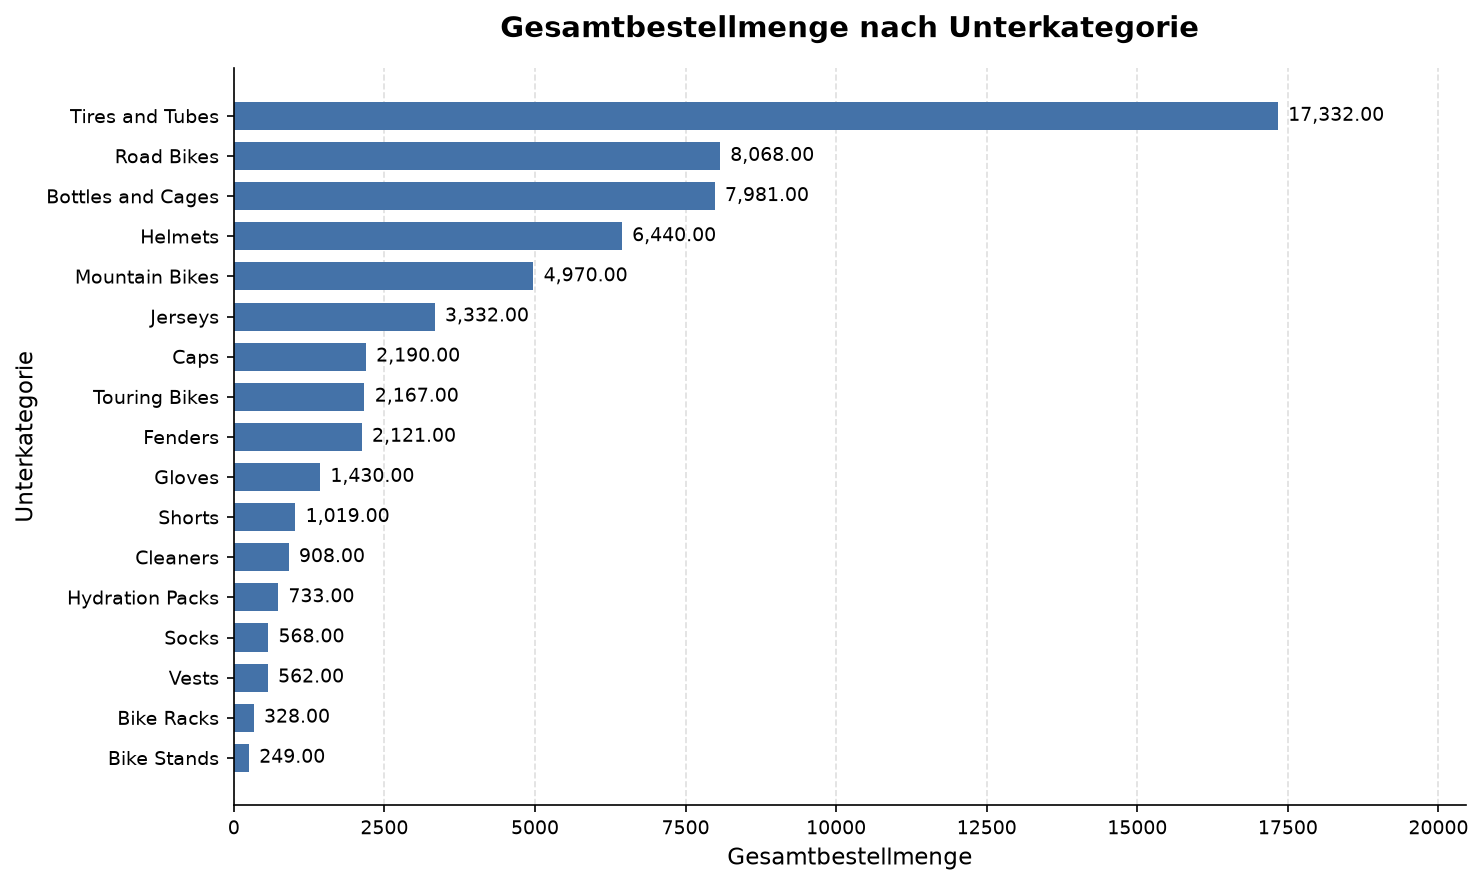

In [10]:
ScientificBarChart(
    sum_sales_count,
    category_col="Subcategory",
    value_col="SumOrderQuantity",
    title="Gesamtbestellmenge nach Unterkategorie",
    xlabel="Gesamtbestellmenge",
    ylabel="Unterkategorie",
).plot()

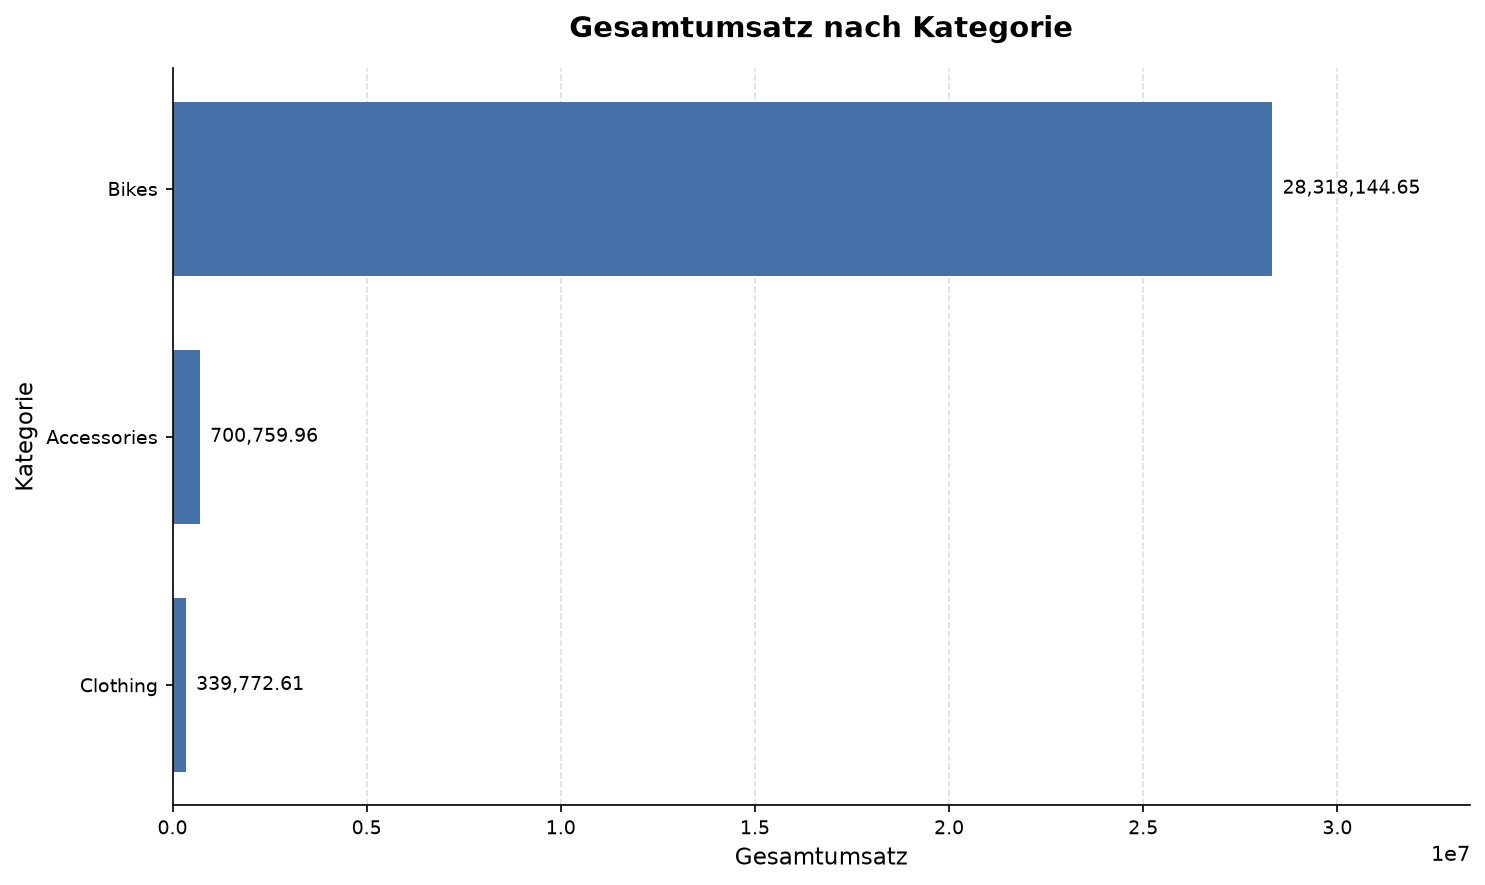

In [11]:
ScientificBarChart(
    sum_sales_amount_category,
    category_col="Category",
    value_col="SumSalesAmount",
    title="Gesamtumsatz nach Kategorie",
    xlabel="Gesamtumsatz",
    ylabel="Kategorie",
).plot()

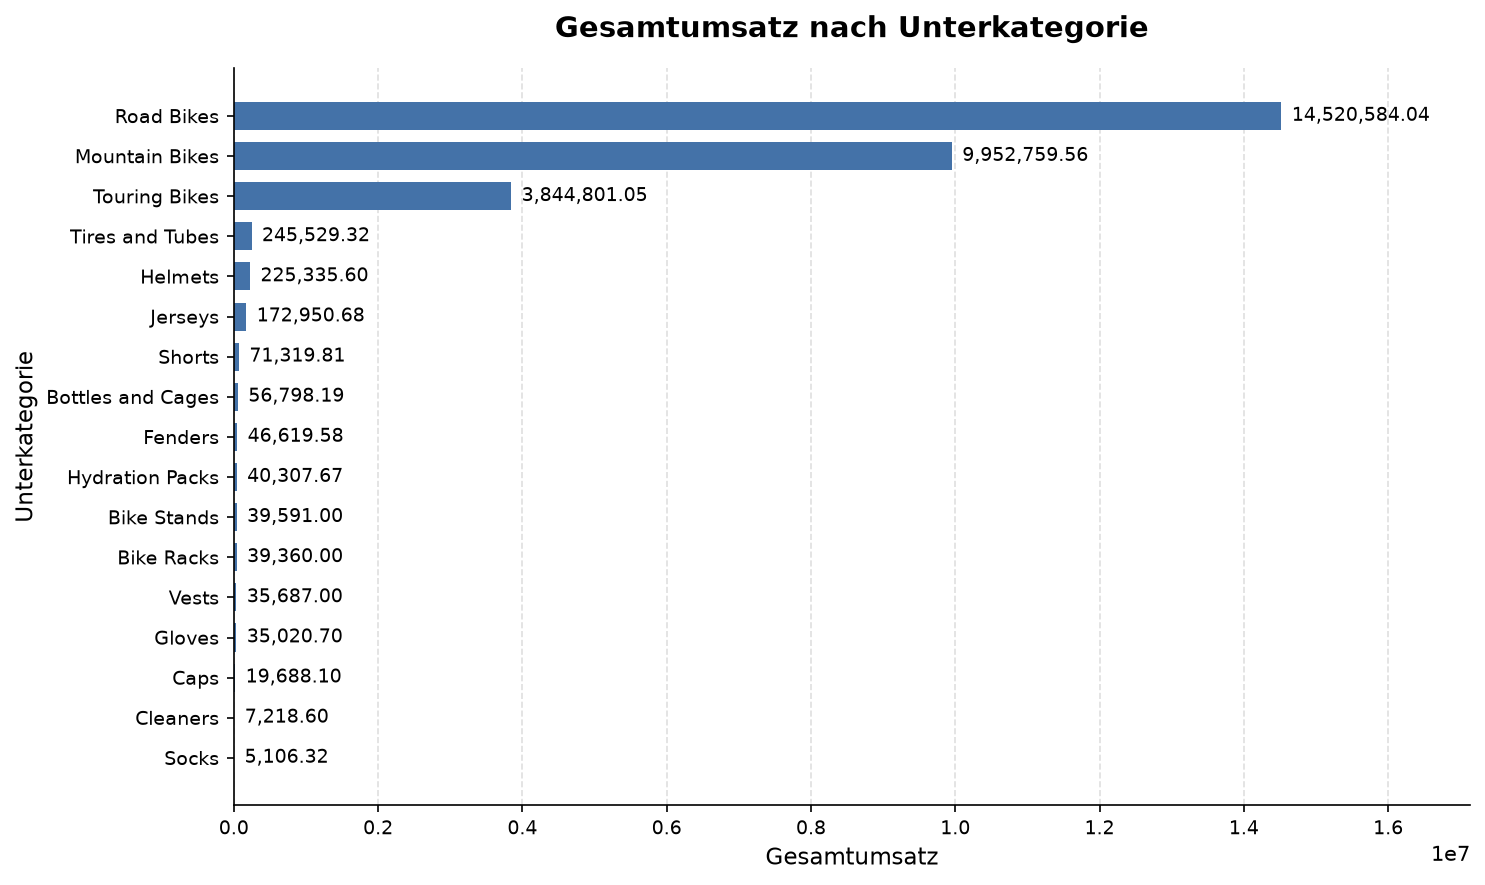

In [12]:
ScientificBarChart(
    sum_sales_amount_subcategory,
    category_col="Subcategory",
    value_col="SumSalesAmount",
    title="Gesamtumsatz nach Unterkategorie",
    xlabel="Gesamtumsatz",
    ylabel="Unterkategorie",
).plot()

### Teilbegutachtung Bikes

In [13]:
bikes_df = df[df["Category"] == "Bikes"]

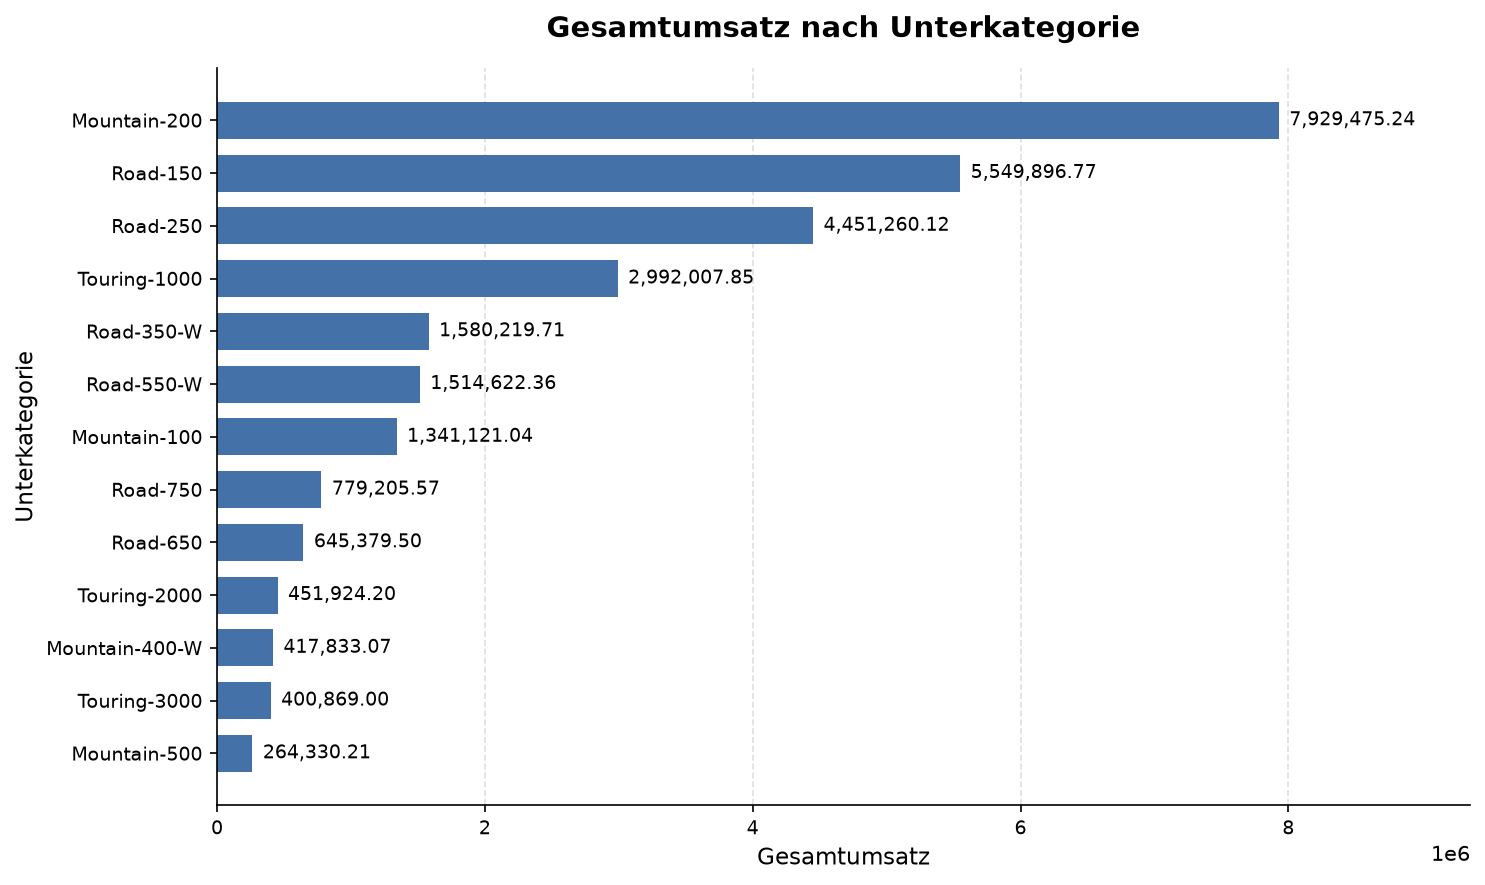

In [14]:
sum_sales_amount_model = calculate_amount_per_column(bikes_df, "Model", "SalesAmount")
ScientificBarChart(
    sum_sales_amount_model,
    category_col="Model",
    value_col="SumSalesAmount",
    title="Gesamtumsatz nach Unterkategorie",
    xlabel="Gesamtumsatz",
    ylabel="Unterkategorie",
).plot()

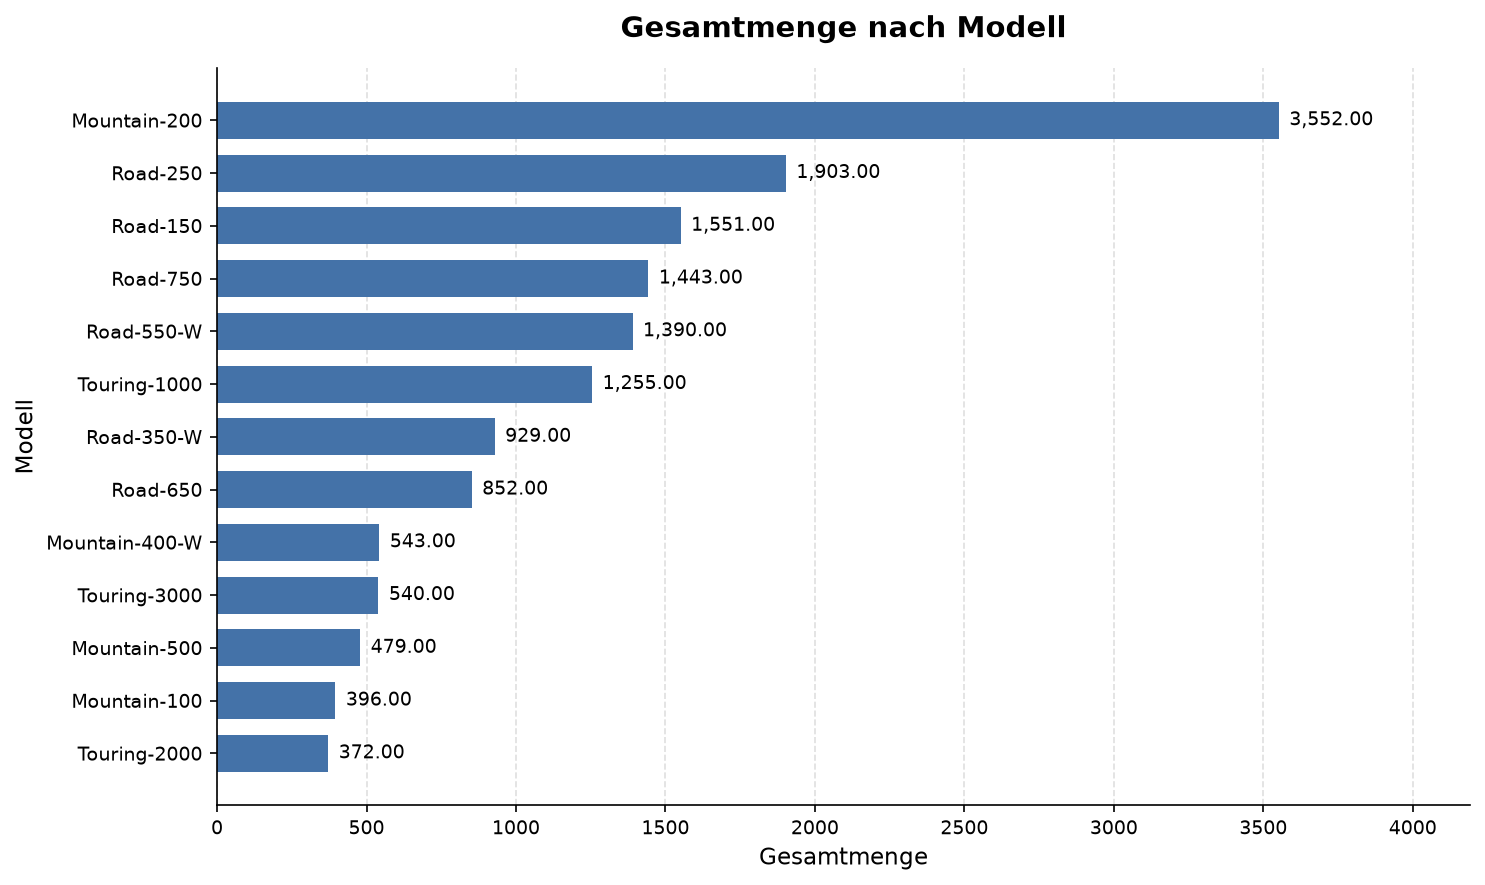

In [15]:
sum_sales_quantity_model = calculate_amount_per_column(
    bikes_df, "Model", "OrderQuantity"
)

ScientificBarChart(
    sum_sales_quantity_model,
    category_col="Model",
    value_col="SumOrderQuantity",
    title="Gesamtmenge nach Modell",
    xlabel="Gesamtmenge",
    ylabel="Modell",
).plot()

### Time Series Analysis

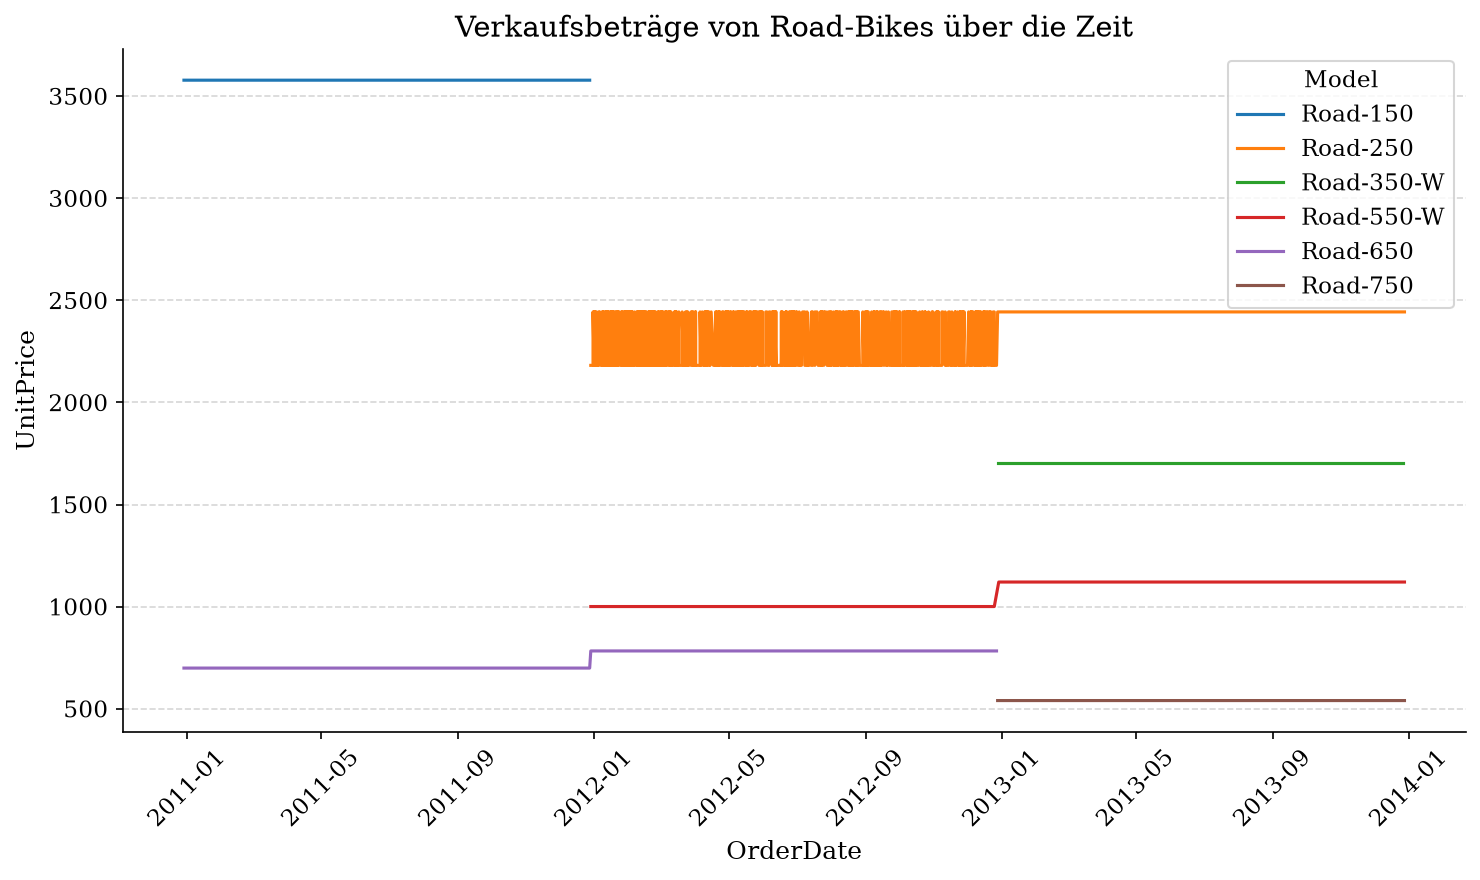

In [16]:
ts_plots = TimeSeriesPlots(bikes_df)

# Stückpreise der Road-Bikes im Zeitverlauf
ts_plots.plot_road_bike_prices()

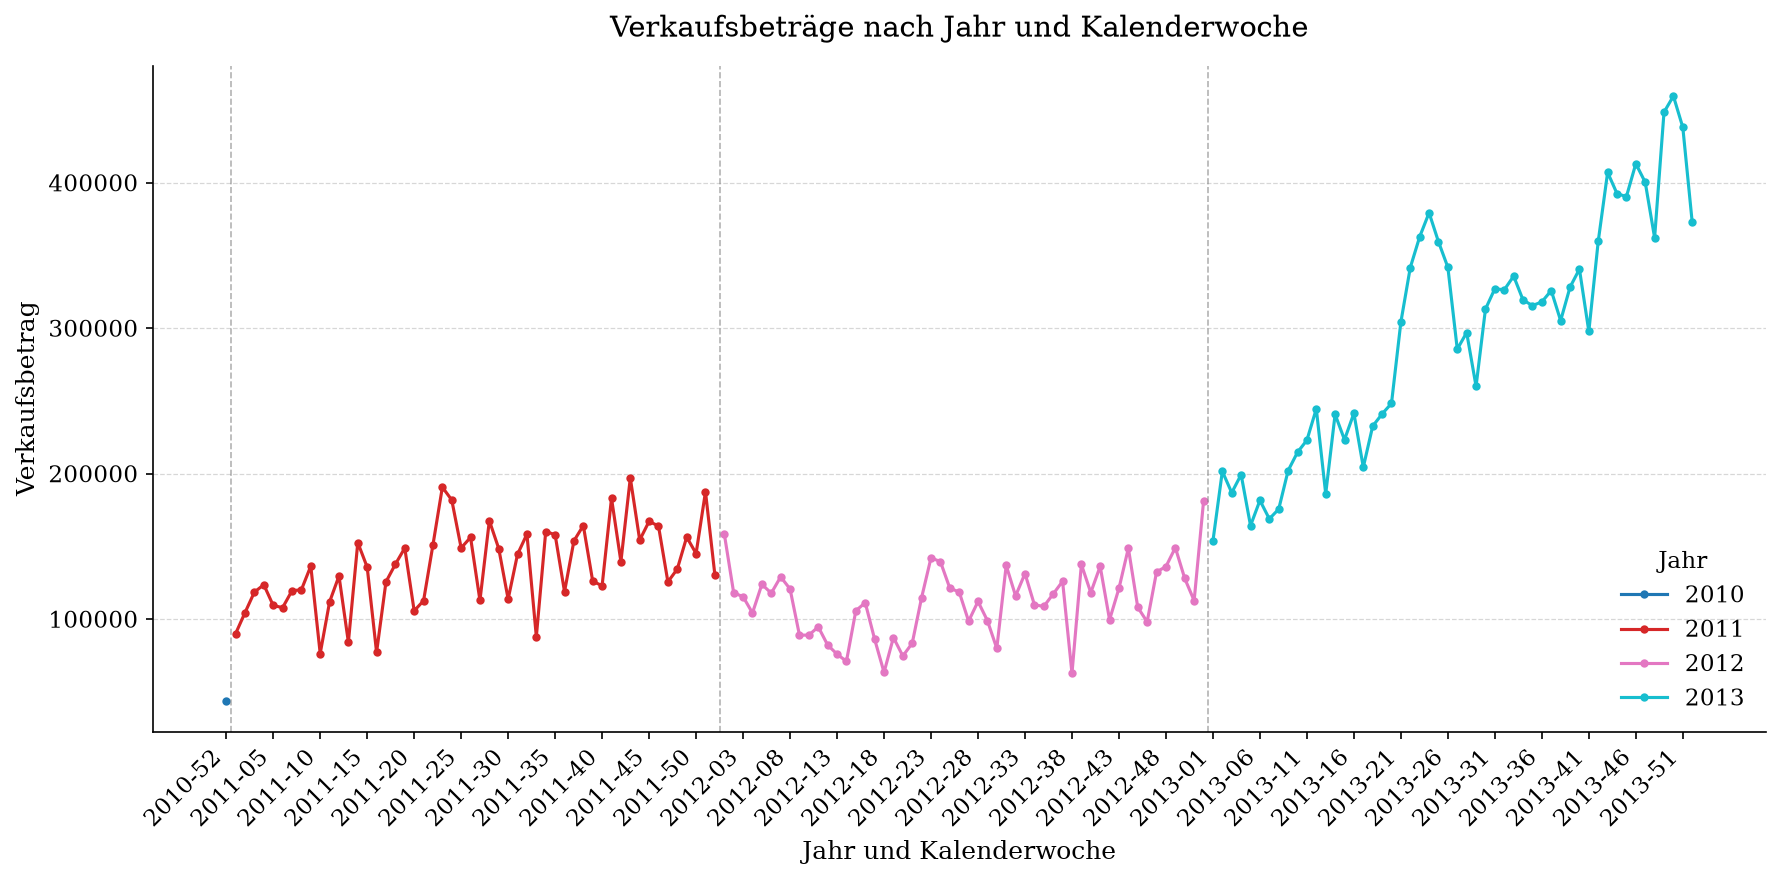

In [17]:
# Verkaufsbeträge nach Kalenderwoche
ts_plots.plot_sales_by_year_week()

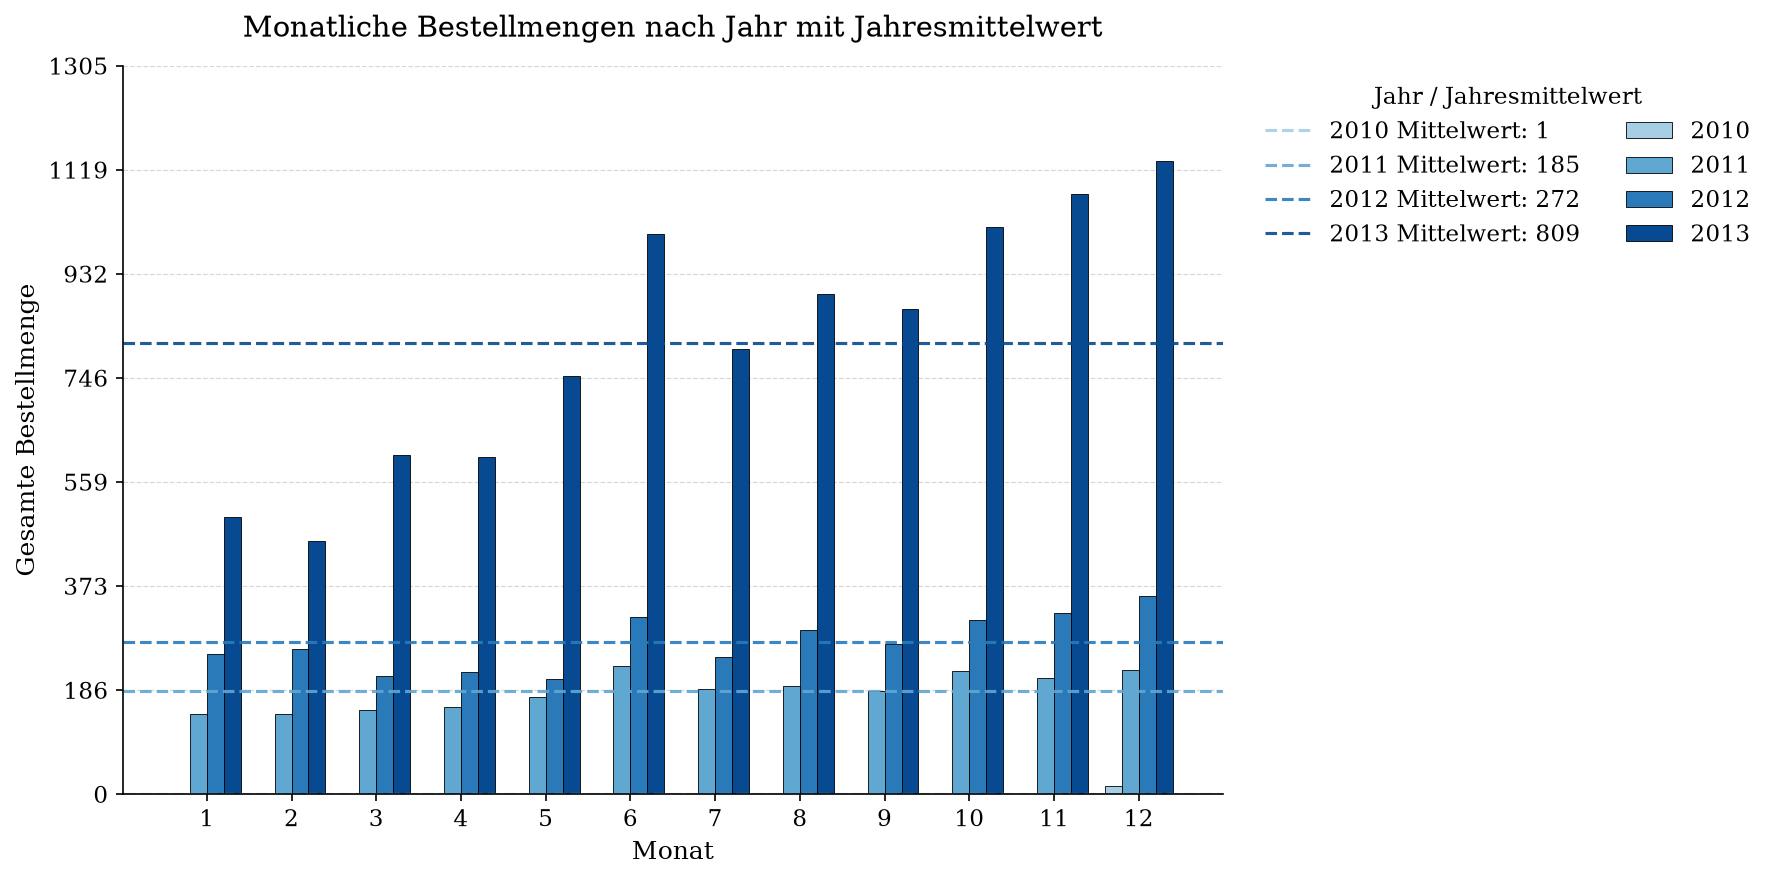

In [18]:
# Monatliche Bestellmengen mit Jahresmittelwerten
ts_plots.plot_monthly_sales_by_year()